In [41]:
import torch
import json
import numpy as np
import os
import h5py
import matplotlib.pyplot as plt

from nets import get_model
from evals import Evaluator
from datasets import build_part_of_dataset_parametrised

exp_data_dir = "results_init_dist_inout_dist"
json_param_file = "generation_script_diff_init_dist_small_range_params.json"

Ninter = 150
eps = 1/np.power(Ninter, 1-1e-4)
dt = 0.1 * eps * eps # reproducing the computation of dt in the .cpp file
M = int(1/dt) + 1
time_skeleton = np.arange(0, M, 1000) # we can start at zero because later on we start with [1:] anyway
time_indices = time_skeleton * dt

In [18]:

with open(json_param_file, "r") as f:
	params = json.load(f)

with open(os.path.join(exp_data_dir, "kwargs.json"), "r") as f:
	args_dict = json.load(f)

with open(os.path.join(exp_data_dir, "indices.json"), "r") as f:
	indices = json.load(f)


xgrid = np.arange(args_dict['lower_bd'], args_dict['upper_bd'], args_dict['grid_size'])
state_dict = torch.load(os.path.join(exp_data_dir, "model_data.pth"))
state_dict = {key.lstrip("net."): arr for key, arr in state_dict.items()}
model, opt = get_model(33, hidden_layers=args_dict["hidden_layers"], learning_rate=args_dict["learning_rate"])
model.net.load_state_dict(state_dict)

<All keys matched successfully>

In [36]:
def create_proto_dataset_from_param_idx(param_dict, idx):
	alph, mult, storage_name = param_dict["alphas"][idx], param_dict["multipliers"][idx], param_dict["storage_names"][idx]

	with h5py.File(storage_name, "r") as f:
		positions_arr = f['drift_results'][:]

	positions_arr = positions_arr.reshape(-1, Ninter)
	part_dataset = build_part_of_dataset_parametrised(xgrid, (alph, mult, None, eps),
		                                                  time_indices, positions_arr,
		                                                  with_init_dist=True)
	return part_dataset, positions_arr

In [28]:
idx_train = indices['in']
idx_val = indices['pout']
idx_tot_val = indices['totout']

In [31]:
tidx = np.linspace(0, 223, num=9, dtype=int)
evaluator_kwargs = dict(network=model,
					  xgrid=xgrid,
					  time_indices=tidx,
					  dt=dt, eps=eps)

In [58]:
proto_dataset_train, train_pos_arr = create_proto_dataset_from_param_idx(param_dict=params, idx=idx_train[0])
proto_dataset_val, val_pos_arr = create_proto_dataset_from_param_idx(param_dict=params, idx=idx_val[2])
proto_dataset_tot_val, tot_val_pos_arr = create_proto_dataset_from_param_idx(param_dict=params, idx=idx_tot_val[0])

In [59]:
evaluator_train = Evaluator(proto_dataset=proto_dataset_train, **evaluator_kwargs)
evaluator_val = Evaluator(proto_dataset=proto_dataset_val, **evaluator_kwargs)
evaluator_totval = Evaluator(proto_dataset=proto_dataset_tot_val, **evaluator_kwargs)

In [60]:
exact_train, neural_train, err = evaluator_train.evaluate_trajectory_exact(xinit=0,
                                                                      time_indices=time_indices,
                                                                      pos_arr=train_pos_arr, with_plots=False)
exact_val, neural_val, err_val = evaluator_val.evaluate_trajectory_exact(xinit=0,
                                                                      time_indices=time_indices,
                                                                      pos_arr=val_pos_arr, with_plots=False)
exact_tot_val, neural_tot_val, err_tot_val = evaluator_val.evaluate_trajectory_exact(xinit=0,
                                                                      time_indices=time_indices,
                                                                      pos_arr=tot_val_pos_arr, with_plots=False)

In [62]:
err

np.float64(0.0010122432477250793)

In [63]:
err_val

np.float64(0.001779681168257887)

In [64]:
err_tot_val

np.float64(0.006784431909048094)

Text(0.5, 1.0, 'storage_narrow_init_dist/N_150_alph_0.35570457795607785_mult_1.096421071389458_init_dist_mixture_11.hdf5')

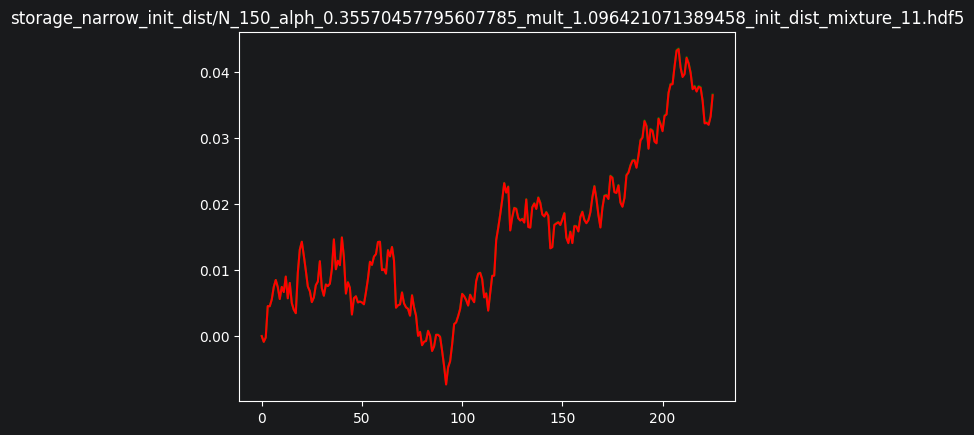

In [65]:
plt.plot(exact_train, color='green')
plt.plot(neural_train, color='red')
plt.title(params['storage_names'][idx_train[0]])

Text(0.5, 1.0, 'storage_narrow_init_dist/N_150_alph_0.43039862632899284_mult_0.9798730859696037_init_dist_mixture_0.hdf5')

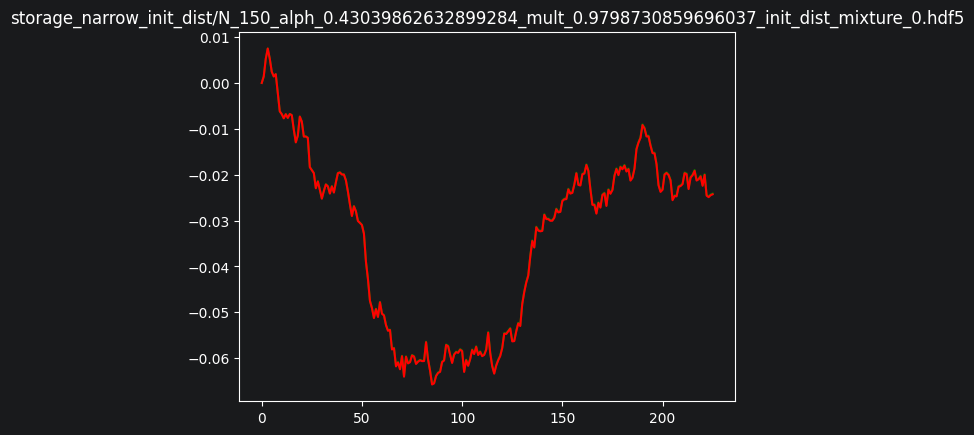

In [66]:
plt.plot(exact_val, color='green')
plt.plot(neural_val, color='red')
plt.title(params['storage_names'][idx_val[0]])

Text(0.5, 1.0, 'storage_narrow_init_dist/N_150_alph_0.44433960510234544_mult_0.943881965779999_init_dist_mixture_13.hdf5')

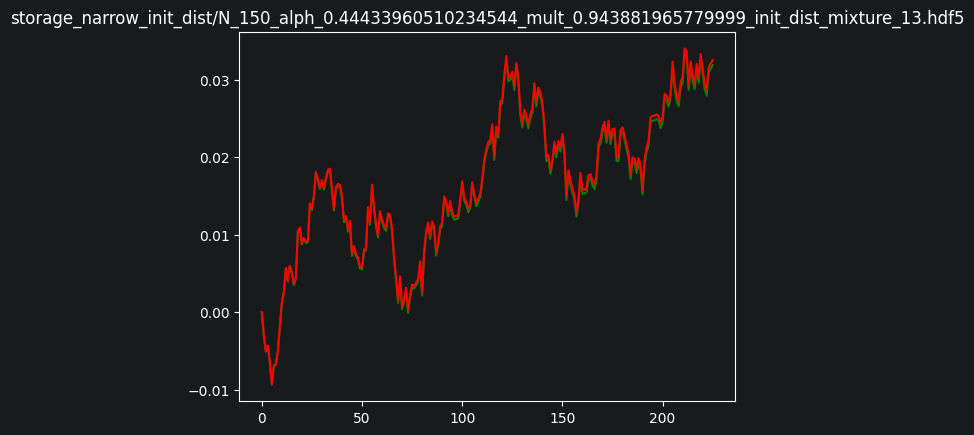

In [67]:
plt.plot(exact_tot_val, color='green')
plt.plot(neural_tot_val, color='red')
plt.title(params['storage_names'][idx_tot_val[0]])